# Longitudinal Wearable Data Visualization

## Overview

This notebook demonstrates reusable Python functions for
visualizing longitudinal wearable measurements.

All data are **synthetic**, representing 20 fictional
participants monitored over 30 days.

The examples demonstrate:

1. Individual longitudinal trajectories
2. Between-participant heterogeneity
3. Missing-data visualization
4. Aligned multivariable trajectories
5. Figure export

These visualizations are intended for computational
demonstration and exploratory analysis, not clinical
decision-making.

## 1. Load synthetic wearable data

The dataset contains daily observations of sleep duration,
nightly HRV (RMSSD), and daily steps.

Four simulated temporal patterns are included:
increasing, decreasing, stable, and fluctuating.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve().parent

if not (
    PROJECT_ROOT / "src" / "wearable_visualization"
).exists():
    raise FileNotFoundError(
        "Run this notebook from the repository's notebooks folder."
    )

sys.path.insert(0, str(PROJECT_ROOT))

from src.wearable_visualization.trajectories import (
    plot_individual_trajectory
)
from src.wearable_visualization.comparisons import (
    plot_participant_comparison
)
from src.wearable_visualization.missingness import (
    plot_missingness_heatmap
)
from src.wearable_visualization.multivariable import (
    plot_multivariable_trajectories
)
from src.wearable_visualization.export import save_figure

df = pd.read_csv(
    PROJECT_ROOT / "data" / "synthetic_longitudinal_data.csv",
    parse_dates=["date"]
)

print("Dataset shape:", df.shape)
print("Participants:", df["participant_id"].nunique())

display(df.head())

Dataset shape: (600, 7)
Participants: 20


,participant_id,date,day,pattern,sleep_duration_min,hrv_rmssd_ms,steps
0,P001,2026-01-01,1,increasing,468.0,NaN,8323.0
1,P001,2026-01-02,2,increasing,453.4,43.4,9677.0
2,P001,2026-01-03,3,increasing,NaN,49.8,10541.0
3,P001,2026-01-04,4,increasing,455.6,51.5,10300.0
4,P001,2026-01-05,5,increasing,438.9,48.1,8942.0


## 2. Individual longitudinal trajectories

Individual plots illustrate temporal changes within
a participant.

Missing observations remain visible as gaps rather
than being interpolated.

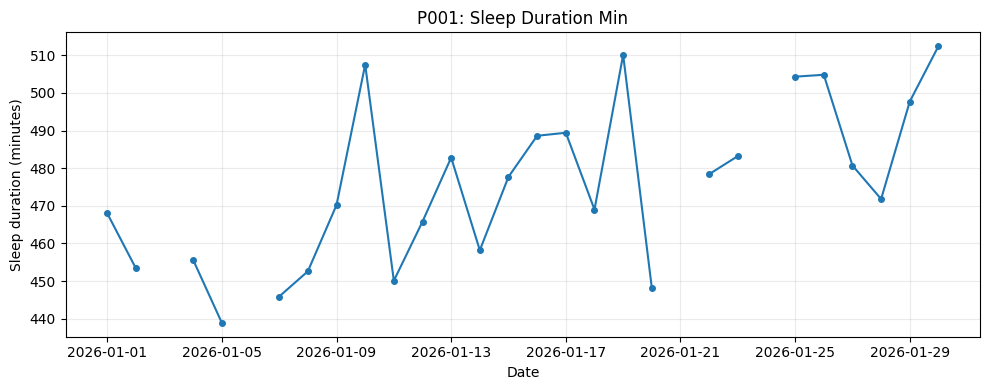

In [2]:
ax = plot_individual_trajectory(
    df,
    participant_id="P001",
    variable="sleep_duration_min"
)

plt.tight_layout()
plt.show()

## 3. Between-participant heterogeneity

Individual trajectories can differ substantially,
even when summarized by a single group mean.

The thick black line represents the mean of available
observations on each study day.

Because measurements may be missing, the participants
contributing to that mean can vary across days.

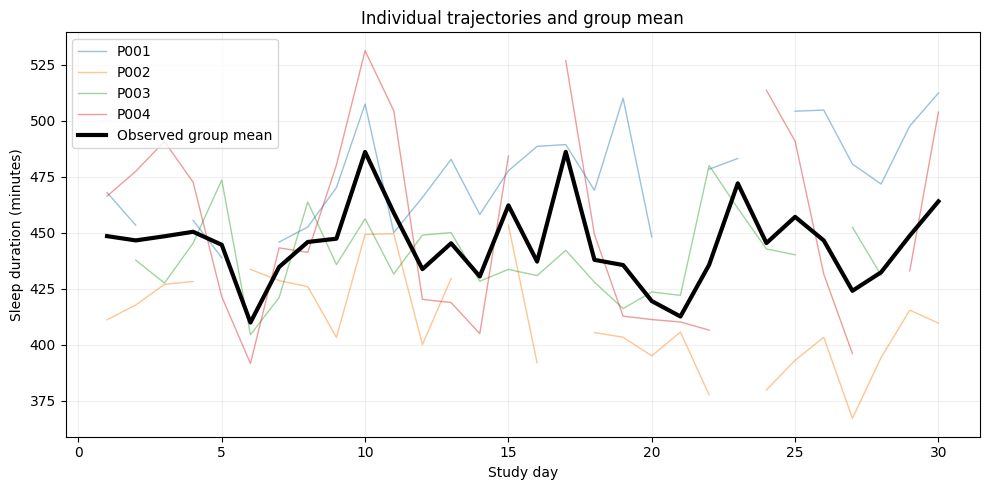

In [3]:
selected_participants = ["P001", "P002", "P003", "P004"]

ax = plot_participant_comparison(
    df,
    variable="sleep_duration_min",
    participant_ids=selected_participants
)

plt.tight_layout()
plt.show()

## 4. Missing-data visualization

This participant-by-day heatmap shows the availability
of sleep-duration measurements.

Blue represents observed measurements and orange
represents missing measurements.

The function also identifies absent participant-day
rows when an expected day sequence is supplied.

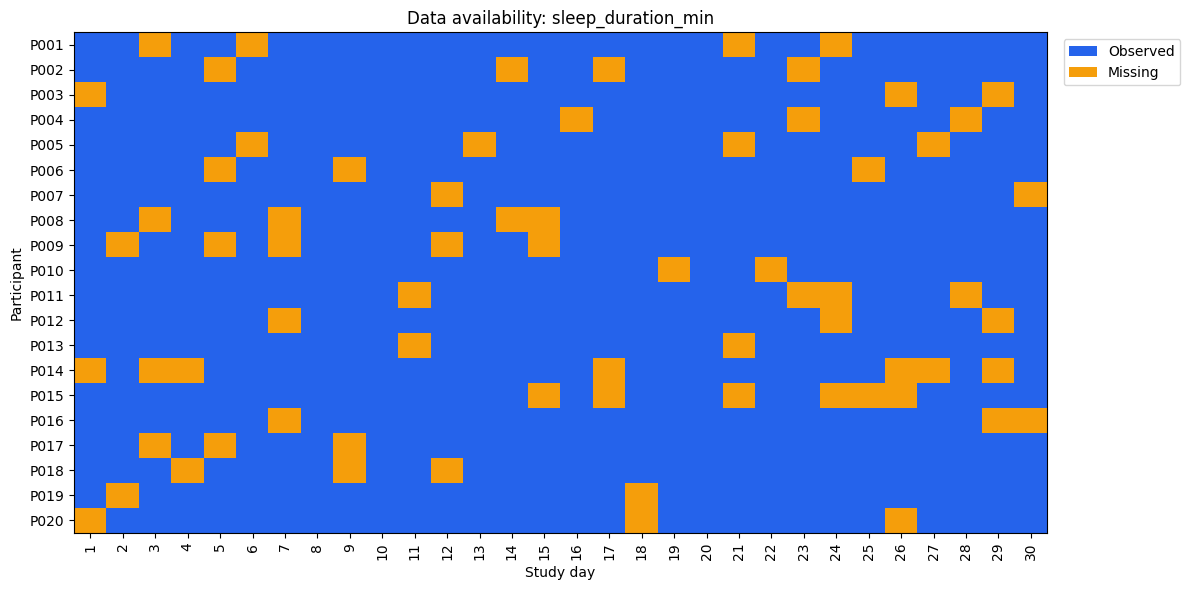

In [4]:
ax = plot_missingness_heatmap(
    df,
    variable="sleep_duration_min",
    expected_days=range(1, 31)
)

plt.tight_layout()
plt.show()

## 5. Aligned multivariable trajectories

Sleep duration, HRV, and daily steps are displayed
on separate y-axes with a shared study-day axis.

This allows visual comparison of temporal patterns
without combining incompatible measurement units.

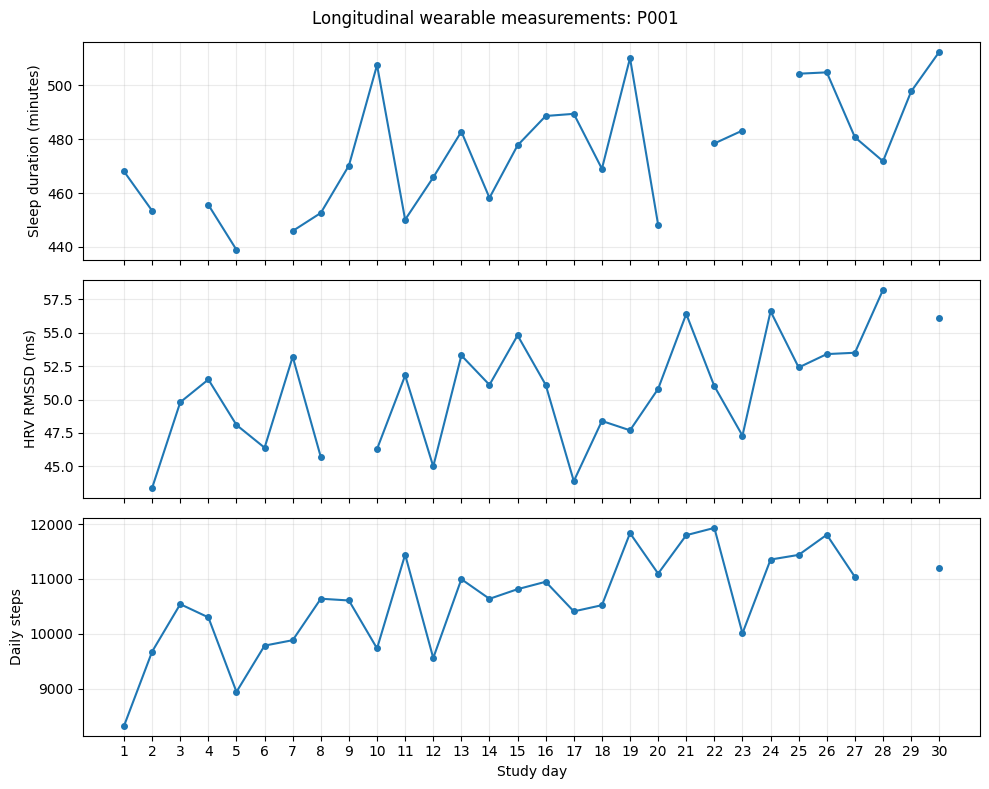

In [5]:
fig, axes = plot_multivariable_trajectories(
    df,
    participant_id="P001",
    expected_days=range(1, 31)
)

plt.show()

## 6. Export scientific figures

Figures can be exported as high-resolution PNG files
and vector PDFs.

The example below saves the multivariable visualization
to the repository's figures folder.

In [6]:
saved_files = save_figure(
    fig,
    filename="synthetic_multivariable_P001",
    output_dir=PROJECT_ROOT / "figures",
    dpi=300
)

for path in saved_files:
    print("Saved:", path.name)

Saved: synthetic_multivariable_P001.png
Saved: synthetic_multivariable_P001.pdf


## 7. Interpretation and limitations

These visualizations demonstrate complementary ways
to explore longitudinal wearable measurements.

- **Individual trajectories** show within-person changes.
- **Participant comparisons** illustrate heterogeneity.
- **Missingness heatmaps** show data availability.
- **Multivariable plots** display aligned measurements.
- **Figure export** supports reproducible communication.

Missing measurements are not automatically imputed.
Observed group means may reflect different participants
across study days.

Visual associations do not establish causal relationships.

The synthetic temporal patterns are illustrative and
do not represent clinical phenotypes or research findings.